In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

In [2]:
dataframe = pd.read_csv(
    "../data/raw/GLDS-570_rna_seq_RSEM_Unnormalized_Counts_rRNArm_GLbulkRNAseq.csv",
    index_col=0,
)
samples = pd.read_csv("../data/samples.csv")

dataframe = dataframe[samples["sample"]]       # keep only your 18 samples, in the same order
dataframe = dataframe.round().astype(int)      # round decimals to whole numbers
print(dataframe.shape)

(56924, 18)


In [ ]:
#keep a gene only if it has at least 10 reads in at least 9 samples.

keep = (dataframe >= 10).sum(axis=1) >= 9
dataframe_f = dataframe[keep]
print(f"Kept {keep.sum():,} of {len(keep):,} genes ({(~keep).sum():,} removed)")

Kept 16,115 of 56,924 genes (40,809 removed)


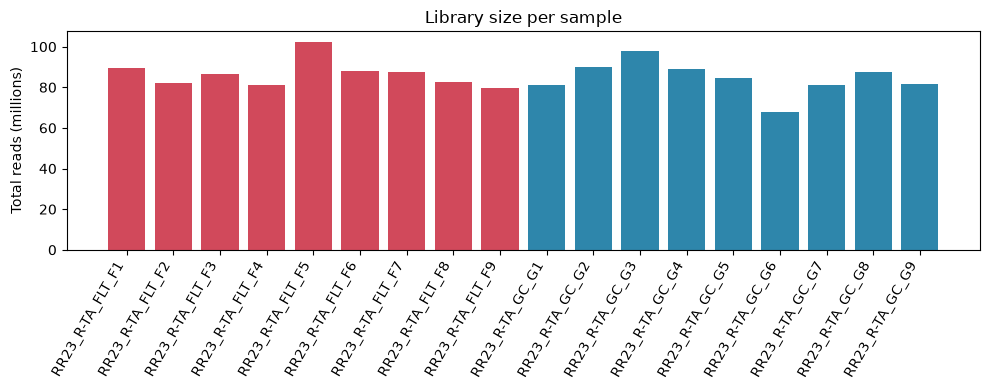

In [5]:
colors = samples["condition"].map({"Flight": "#d1495b", "Ground": "#2e86ab"})

lib_m = dataframe_f.sum(axis=0) / 1e6
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(lib_m.index, lib_m.values, color=colors)
ax.set_ylabel("Total reads (millions)")
ax.set_title("Library size per sample")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig("../figures/01_library_sizes.png", dpi=200)
plt.show()

In [7]:
cpm = dataframe_f / dataframe_f.sum(axis=0) * 1e6     # counts per million: adjusts for depth
logcpm = np.log2(cpm + 1)                        # log scale, so huge genes don't dominate

top_genes = logcpm.var(axis=1).sort_values(ascending=False).index[:500]
X = logcpm.loc[top_genes].T                      # samples as rows, genes as columns

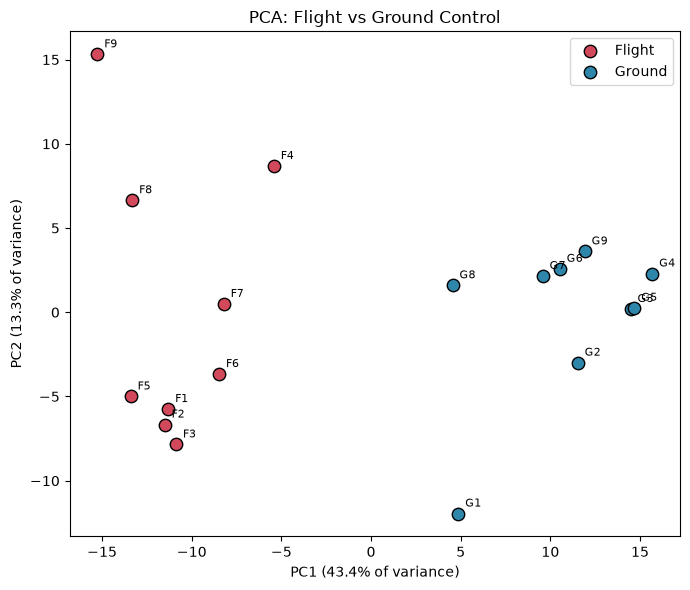

In [8]:
pca = PCA(n_components=2)
pcs = pca.fit_transform(X - X.mean())
var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(7, 6))
for cond, col in [("Flight", "#d1495b"), ("Ground", "#2e86ab")]:
    m = (samples["condition"] == cond).values
    ax.scatter(pcs[m, 0], pcs[m, 1], c=col, s=80, label=cond, edgecolor="k")
for i, name in enumerate(samples["sample"]):
    ax.annotate(name.split("_")[-1], (pcs[i, 0], pcs[i, 1]), fontsize=8,
                xytext=(5, 5), textcoords="offset points")
ax.set_xlabel(f"PC1 ({var[0]:.1f}% of variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1f}% of variance)")
ax.set_title("PCA: Flight vs Ground Control")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/02_pca.png", dpi=200)
plt.show()

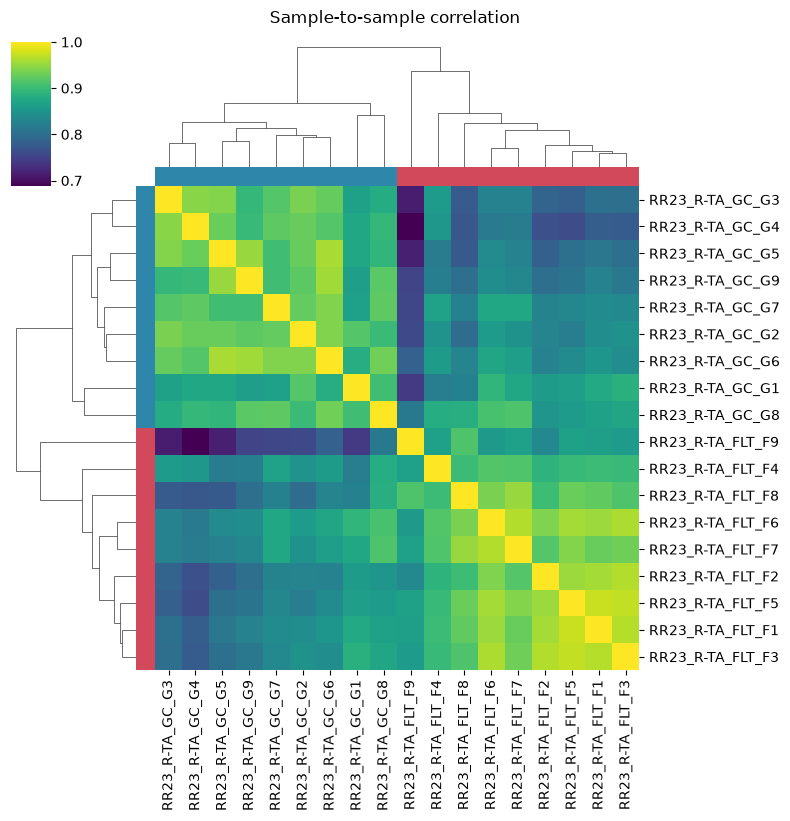

In [9]:
corr = logcpm.loc[top_genes].corr()
g = sns.clustermap(corr, cmap="viridis", row_colors=colors.values,
                   col_colors=colors.values, figsize=(8, 8))
g.fig.suptitle("Sample-to-sample correlation", y=1.02)
g.savefig("../figures/03_sample_correlation.png", dpi=200)
plt.show()

In [10]:
dataframe_f.to_csv("../data/processed/dataframe_filtered.csv")